# Assignment 1: Predicting House Prices with Neural Networks in PyTorch

In this notebook you will:

- Load a regression dataset from Hugging Face Datasets (`gvlassis/california_housing`).
- Use the provided **train / validation / test** splits.
- Do a quick exploratory check with pandas (optional, for intuition and missing-value checks).
- Convert data into NumPy arrays, scale features using `StandardScaler` fitted on the training set only.
- Convert data to PyTorch tensors and use `TensorDataset` + `DataLoader`.
- Define and train a custom MLP regressor in PyTorch with a manual training loop.
- Run a regularization experiment (baseline vs regularized model).
- Evaluate the final model on a held-out test set.

Cells marked with `# === TODO ===` are where you are expected to write code.


## 1. Setup and dataset loading

In [ ]:
# Imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from datasets import load_dataset
import numpy as np
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import random

# Seed the environment
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

### Device and tensors

Neural networks usually run much faster on GPU when available.

PyTorch works with **tensors**, which are like NumPy arrays but optimized for deep learning and automatic differentiation. Most neural-network operations expect tensors as inputs, so all your data eventually needs to be converted into them.

* `device` tells you whether you are using CPU or GPU.
* Always move:

  * the **model** to `device`, and
  * each **batch** `(X_batch, y_batch)` to `device` inside the training loop.

To learn more about tensors, see the official PyTorch intro:
[https://pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html](https://pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html)




### What is `dataset` in Hugging Face?

When you load a dataset:

```python
dataset = load_dataset("some/dataset_name")
```

you get a **DatasetDict**, which is simply a dictionary containing the dataset splits:

- `dataset["train"]`
- `dataset["validation"]`
- `dataset["test"]`

Each split is a **Dataset**, which behaves like a lightweight table:

- `num_rows` = number of samples  
- `column_names` = feature names  
- each row is a Python dict, for example:

```python
dataset["train"][0]
{
    "feature1": ...,
    "feature2": ...,
    ...
}
```

These datasets are optimized for machine learning workflows, not for full exploratory analysis. To learn more about datasets in Hugging Face Datasets, see: [https://huggingface.co/docs/datasets/index](https://huggingface.co/docs/datasets/index)


In [ ]:
# Load the California housing dataset from Hugging Face Datasets.
# We use the 'gvlassis/california_housing' version, which already provides
# train / validation / test splits.

dataset = load_dataset("gvlassis/california_housing")
print(dataset)
print("Splits:", dataset.keys())
print("Train rows:", dataset["train"].num_rows)
print("Validation rows:", dataset["validation"].num_rows)
print("Test rows:", dataset["test"].num_rows)
print("Features:", dataset["train"].column_names)


'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/gvlassis/california_housing/resolve/17110e600427385a20e8358b00adc9b032d185ff/california_housing.py
Retrying in 1s [Retry 1/5].
Using the latest cached version of the dataset since gvlassis/california_housing couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'default' at C:\Users\User\.cache\huggingface\datasets\gvlassis___california_housing\default\0.0.0\17110e600427385a20e8358b00adc9b032d185ff (last modified on Fri Dec 26 20:01:35 2025).


DatasetDict({
    train: Dataset({
        features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal'],
        num_rows: 16640
    })
    validation: Dataset({
        features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal'],
        num_rows: 2000
    })
})
Splits: dict_keys(['train', 'validation', 'test'])
Train rows: 16640
Validation rows: 2000
Test rows: 2000
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']



## 2. Quick exploratory check with pandas

Hugging Face Datasets are efficient and work well with PyTorch, but it can be helpful to:

- Look at a few rows in a familiar table format.
- Quickly check for missing values or weird distributions.

Here we convert only the **training split** to a pandas DataFrame for inspection.  
The actual model pipeline later will use NumPy + PyTorch tensors.


In [ ]:
# You can run this cell to preview the training data using pandas.
# This is for exploration only.

import pandas as pd

df_train = dataset["train"].to_pandas()
df_train.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# Quick missing-value and summary checks (optional EDA).

df_train.isna().sum(), df_train.describe()


(MedInc         0
 HouseAge       0
 AveRooms       0
 AveBedrms      0
 Population     0
 AveOccup       0
 Latitude       0
 Longitude      0
 MedHouseVal    0
 dtype: int64,
              MedInc      HouseAge      AveRooms     AveBedrms    Population  \
 count  16640.000000  16640.000000  16640.000000  16640.000000  16640.000000   
 mean       3.797641     29.221995      5.396218      1.101687   1436.939123   
 std        1.867145     12.797845      2.648682      0.511507   1159.762831   
 min        0.499900      1.000000      0.846154      0.375000      3.000000   
 25%        2.526300     19.000000      4.379310      1.007401    792.000000   
 50%        3.474500     30.000000      5.166053      1.050725   1168.000000   
 75%        4.635475     38.000000      6.000000      1.101127   1727.000000   
 max       15.000100     52.000000    141.909091     34.066667  35682.000000   
 
            AveOccup      Latitude     Longitude   MedHouseVal  
 count  16640.000000  16640.000000  

### Why deep learning needs preprocessing

Even when a dataset is already clean (no missing values, proper splits), neural networks still need a few preprocessing steps so that **gradient descent** works well:

- **Scale features** so gradients are stable and training converges faster.
- **Convert data to tensors** so PyTorch can compute gradients.
- **Create mini-batches and shuffle** the training data for efficient, unbiased updates.
- **Apply the same transforms** to train, validation, and test (but fit scalers on train only to avoid leakage).


## 3. From Hugging Face datasets to scaled tensors (via NumPy)

Now we build the actual preprocessing pipeline for the model:

1. Use the **provided splits**:
   - `train_ds = dataset["train"]`
   - `val_ds = dataset["validation"]`
   - `test_ds = dataset["test"]`
2. Extract feature matrices `X_*` and target vectors `y_*` into NumPy arrays.
3. Fit `StandardScaler` on **training features only**.
4. Transform train/validation/test with that scaler.
5. Convert everything to PyTorch tensors.


In [ ]:
# Create handles for each split from the dataset dict.

train_ds = dataset["train"]
val_ds = dataset["validation"]
test_ds = dataset["test"]

train_ds, val_ds, test_ds


(Dataset({
     features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal'],
     num_rows: 16640
 }),
 Dataset({
     features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal'],
     num_rows: 2000
 }),
 Dataset({
     features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal'],
     num_rows: 2000
 }))

In [ ]:
# === TODO ===

target_col = 'MedHouseVal'
feature_names = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

feature_names, target_col

(['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'MedHouseVal')

In [ ]:
import numpy as np

# Helper function to convert a HF dataset split into X (features) and y (target) NumPy arrays.

def hf_to_numpy_xy(ds, feature_names, target_name):
    """Convert a Hugging Face Dataset into (X, y) NumPy arrays.

    X should have shape [num_samples, num_features] (dtype float32).
    y should have shape [num_samples, 1] (dtype float32).
    """
    X_list = []
    y_list = []
    for example in ds:
        # fill these lists
        X_list.append([example[col] for col in feature_names])
        y_list.append(example[target_name])

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.float32).reshape(-1, 1)
    return X, y

In [ ]:
# === TODO ===
# Use hf_to_numpy_xy to create NumPy arrays for train/val/test.

X_train_np, y_train_np = hf_to_numpy_xy(train_ds, feature_names, target_col)
X_val_np, y_val_np = hf_to_numpy_xy(val_ds, feature_names, target_col)
X_test_np, y_test_np = hf_to_numpy_xy(test_ds, feature_names, target_col)

X_train_np.shape, X_val_np.shape, X_test_np.shape, y_train_np.shape

((16640, 8), (2000, 8), (2000, 8), (16640, 1))


### StandardScaler on your dataset

We now standardize the features using `StandardScaler` from scikit-learn.

**Important:**  
- Fit the scaler on **training features only**.  
- Use the same scaler to transform training, validation, and test features.


In [ ]:
# === TODO ===

scaler = StandardScaler()

# 1. Fit on training features
scaler.fit(X_train_np)

# 2. Transform train, val, test features
X_train_scaled = scaler.transform(X_train_np)
X_val_scaled = scaler.transform(X_val_np)
X_test_scaled = scaler.transform(X_test_np)

X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape

((16640, 8), (2000, 8), (2000, 8))

In [ ]:
# === TODO ===
# Convert scaled NumPy arrays into PyTorch tensors.

X_train = torch.from_numpy(X_train_scaled).float()
y_train = torch.from_numpy(y_train_np).float()

X_val = torch.from_numpy(X_val_scaled).float()
y_val = torch.from_numpy(y_val_np).float()

X_test = torch.from_numpy(X_test_scaled).float()
y_test = torch.from_numpy(y_test_np).float()

X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

(torch.Size([16640, 8]),
 torch.Size([16640, 1]),
 torch.Size([2000, 8]),
 torch.Size([2000, 1]),
 torch.Size([2000, 8]),
 torch.Size([2000, 1]))


## 4. TensorDataset and DataLoaders

We now wrap our tensors into `TensorDataset` objects and create DataLoaders for:

- Training (shuffled)
- Validation (no shuffle)
- Test (no shuffle)

This is the final bridge into the deep learning training loop.

It is a good habit to:
- check one batch shape with `next(iter(train_loader))`
- make sure it matches `[batch_size, num_features]` before starting training.


In [ ]:
# === TODO ===
# Create TensorDatasets and DataLoaders.

batch_size = 64  # you can experiment with this

# Create TensorDataset objects
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

len(train_loader), len(val_loader), len(test_loader)

(260, 32, 32)

In [ ]:
import torch

# Optional: inspect one batch shape

X_batch, y_batch = next(iter(train_loader))

print(X_batch.shape, y_batch.shape)

torch.Size([64, 8]) torch.Size([64, 1])


## 5. Define your MLP regressor

Define a simple MLP (multi-layer perceptron) with:

- Input dimension = number of features.
- At least two hidden layers with non-linear activations.
- Output dimension = 1 (regression target).

For this assignment, using **ReLU** activations is a good default:
- ReLU keeps gradients from vanishing (better than sigmoid/tanh for deep nets).
- For regression, keep the **last layer linear** (no activation on the output).


In [ ]:
# === TODO ===
# Define a baseline MLP model for regression.

input_dim = X_train.shape[1]

class RegressorNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        # Define your layers here:
        self.fc1 = nn.Linear(input_dim, 64)  # Input layer to first hidden layer
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(64, 32)         # First hidden layer to second hidden layer
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(32, 1)          # Second hidden layer to output layer (regression, so 1 output)

    def forward(self, x):
        # Implement the forward pass
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)  # No activation on the output layer for regression
        return x

model = RegressorNet(input_dim).to(device)
model

RegressorNet(
  (fc1): Linear(in_features=8, out_features=64, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=32, out_features=1, bias=True)
)

## 6. Loss function, optimizer, and metric

Use:

- Mean Squared Error (MSE) as the training loss.
- Root Mean Squared Error (RMSE) as an evaluation metric.
- Adam optimizer (or SGD with momentum) with a reasonable learning rate and optional weight decay (L2).

Learning rate is one of the most important hyperparameters:
- Too high: training can diverge (loss explodes).
- Too low: training is very slow or gets stuck.


In [ ]:
# === TODO ===
# Define loss function, RMSE metric, and optimizer.

criterion = nn.MSELoss()

def rmse(preds, targets):
    return torch.sqrt(criterion(preds, targets))

learning_rate = 1e-3
weight_decay = 1e-4  # you can experiment with this

optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

## 7. Training and evaluation loops

Implement the manual training loop:

- `train_one_epoch` for one pass over the training DataLoader.
- `evaluate` for computing loss and RMSE over a given DataLoader (validation or test).

Inside these functions, remember to:
- move batches to `device` (`X_batch.to(device)` and `y_batch.to(device)`)
- call `model.train()` for training and `model.eval()` for evaluation


In [ ]:
# === TODO ===
# Implement train_one_epoch and evaluate.

def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()  # Set the model to training mode
    total_loss = 0
    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Forward pass
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
    return total_loss / len(dataloader)


def evaluate(model, dataloader, criterion, device):
    model.eval()  # Set the model to evaluation mode
    total_loss = 0
    total_rmse = 0
    with torch.no_grad():  # Disable gradient calculation for evaluation
        for X_batch, y_batch in dataloader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            total_loss += loss.item()
            total_rmse += rmse(predictions, y_batch).item()

    avg_loss = total_loss / len(dataloader)
    avg_rmse = total_rmse / len(dataloader)
    return avg_loss, avg_rmse

In [ ]:
# === TODO ===
# Train the baseline model for several epochs, tracking train and validation loss.

num_epochs = 50

train_losses = []
val_losses = []
val_rmses = []

for epoch in range(1, num_epochs + 1):
    # 1. Train for one epoch
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    train_losses.append(train_loss)

    # 2. Evaluate on validation set
    val_loss, val_rmse = evaluate(model, val_loader, criterion, device)
    val_losses.append(val_loss)
    val_rmses.append(val_rmse)

    # 3. Print progress every few epochs
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch}/{num_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val RMSE: {val_rmse:.4f}")

Epoch 1/50 | Train Loss: 1.3794 | Val Loss: 0.8601 | Val RMSE: 0.8683
Epoch 5/50 | Train Loss: 0.3603 | Val Loss: 0.5767 | Val RMSE: 0.7259
Epoch 10/50 | Train Loss: 0.3279 | Val Loss: 0.6276 | Val RMSE: 0.7572
Epoch 15/50 | Train Loss: 0.2920 | Val Loss: 0.5447 | Val RMSE: 0.7048
Epoch 20/50 | Train Loss: 0.2821 | Val Loss: 0.5528 | Val RMSE: 0.7117
Epoch 25/50 | Train Loss: 0.2870 | Val Loss: 0.6444 | Val RMSE: 0.7766
Epoch 30/50 | Train Loss: 0.2744 | Val Loss: 0.5866 | Val RMSE: 0.7345
Epoch 35/50 | Train Loss: 0.2696 | Val Loss: 0.5888 | Val RMSE: 0.7430
Epoch 40/50 | Train Loss: 0.2592 | Val Loss: 0.5555 | Val RMSE: 0.7158
Epoch 45/50 | Train Loss: 0.2586 | Val Loss: 0.5277 | Val RMSE: 0.6920
Epoch 50/50 | Train Loss: 0.2537 | Val Loss: 0.5277 | Val RMSE: 0.6969


## 8. Training curves and regularization experiment

In this section you will:

1. Plot the training and validation loss curves for the **baseline** model.
2. Plot the validation RMSE curve.
3. Create **one regularized variant** of your model (for example, add dropout or increase weight decay).
4. Train the regularized model and plot its validation loss curve.


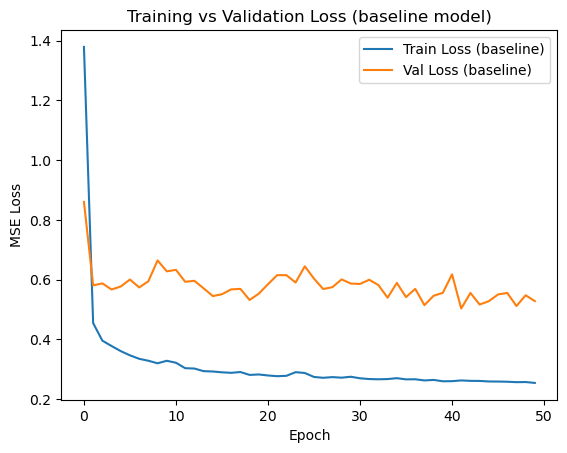

In [ ]:
# Plot training and validation loss for the baseline model.

plt.figure()
plt.plot(train_losses, label="Train Loss (baseline)")
plt.plot(val_losses, label="Val Loss (baseline)")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.title("Training vs Validation Loss (baseline model)")
plt.show()


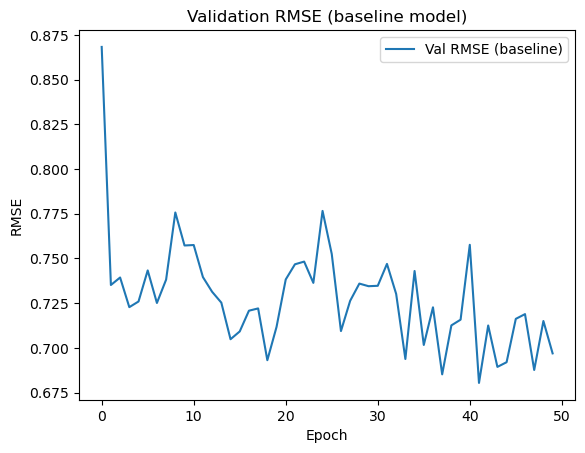

In [ ]:
# Plot validation RMSE for the baseline model.

plt.figure()
plt.plot(val_rmses, label="Val RMSE (baseline)")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.title("Validation RMSE (baseline model)")
plt.show()


In [ ]:
import torch.nn as nn
import torch.optim as optim

# === TODO ===
# Define and train ONE regularized model variant.
# For example: same architecture with dropout + stronger weight decay.

class RegressorNetDropout(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.2):
        super().__init__()
        # Define a similar network but with dropout layers
        self.fc1 = nn.Linear(input_dim, 64)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.dropout1(x)
        x = self.relu2(self.fc2(x))
        x = self.dropout2(x)
        x = self.fc3(x)
        return x

model_reg = RegressorNetDropout(input_dim).to(device)
# e.g. Adam with different weight_decay
optimizer_reg = optim.Adam(model_reg.parameters(), lr=learning_rate, weight_decay=1e-3) # Increased weight decay

num_epochs_reg = 50
train_losses_reg = []
val_losses_reg = []
val_rmses_reg = [] # Added to track RMSE for regularized model

print("Training Regularized Model...")
for epoch in range(1, num_epochs_reg + 1):
    # Train and evaluate the regularized model
    train_loss_reg = train_one_epoch(model_reg, train_loader, optimizer_reg, criterion, device)
    train_losses_reg.append(train_loss_reg)

    val_loss_reg, val_rmse_reg = evaluate(model_reg, val_loader, criterion, device)
    val_losses_reg.append(val_loss_reg)
    val_rmses_reg.append(val_rmse_reg)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch}/{num_epochs_reg} | Train Loss (Reg): {train_loss_reg:.4f} | Val Loss (Reg): {val_loss_reg:.4f} | Val RMSE (Reg): {val_rmse_reg:.4f}")


Training Regularized Model...
Epoch 1/50 | Train Loss (Reg): 1.5216 | Val Loss (Reg): 1.0042 | Val RMSE (Reg): 0.9518
Epoch 5/50 | Train Loss (Reg): 0.4895 | Val Loss (Reg): 0.6425 | Val RMSE (Reg): 0.7731
Epoch 10/50 | Train Loss (Reg): 0.4168 | Val Loss (Reg): 0.5855 | Val RMSE (Reg): 0.7364
Epoch 15/50 | Train Loss (Reg): 0.3841 | Val Loss (Reg): 0.6189 | Val RMSE (Reg): 0.7531
Epoch 20/50 | Train Loss (Reg): 0.3633 | Val Loss (Reg): 0.5878 | Val RMSE (Reg): 0.7320
Epoch 25/50 | Train Loss (Reg): 0.3565 | Val Loss (Reg): 0.5871 | Val RMSE (Reg): 0.7305
Epoch 30/50 | Train Loss (Reg): 0.3394 | Val Loss (Reg): 0.5801 | Val RMSE (Reg): 0.7203
Epoch 35/50 | Train Loss (Reg): 0.3331 | Val Loss (Reg): 0.5726 | Val RMSE (Reg): 0.7168
Epoch 40/50 | Train Loss (Reg): 0.3280 | Val Loss (Reg): 0.6094 | Val RMSE (Reg): 0.7482
Epoch 45/50 | Train Loss (Reg): 0.3281 | Val Loss (Reg): 0.5782 | Val RMSE (Reg): 0.7170
Epoch 50/50 | Train Loss (Reg): 0.3228 | Val Loss (Reg): 0.5783 | Val RMSE (Reg): 

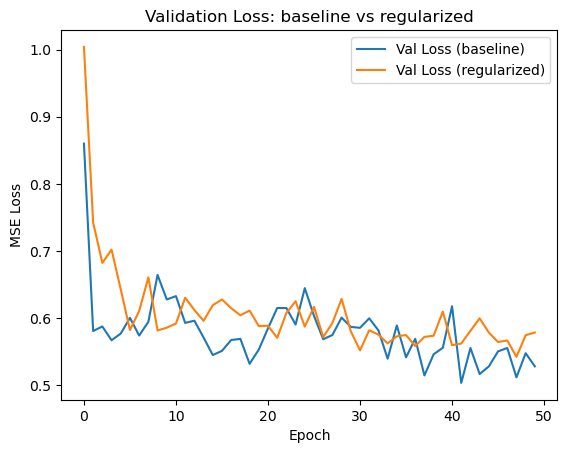

In [ ]:
# Plot validation loss for baseline vs regularized model.

plt.figure()
plt.plot(val_losses, label="Val Loss (baseline)")
plt.plot(val_losses_reg, label="Val Loss (regularized)")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.title("Validation Loss: baseline vs regularized")
plt.show()

### Analysis

Based on the training and validation curves for both the baseline and regularized models: (my answers below each question)

- Does the baseline model show signs of underfitting, overfitting, or a reasonable tradeoff?

-The divergence between the training loss (which keeps decreasing) and the validation loss/RMSE (which decrease initially but then plateau or slightly increase/fluctuate) is a classic indicator of overfitting. The model is becoming too specialized to the training data and is losing its ability to generalize to new, unseen data (the validation set). If the model were underfitting, both training and validation losses would be high and likely flat or decreasing very slowly. A reasonable trade-off would show both losses decreasing in parallel and eventually flattening out without a significant gap.
So The baseline model shows clear signs of overfitting. The training loss continues to decrease, while the validation loss and RMSE fluctuate and remain significantly higher than the training loss, indicating that the model is learning noise or specific patterns in the training data that do not generalize well to the validation set.


- How did your regularization change affect validation loss and RMSE?

 -Positively for the better. The regularization generally led to slightly higher validation loss and RMSE during training compared to the baseline model. For instance, the baseline's best validation RMSE was 0.6920, while the regularized model's best was 0.7168. However, this apparent trade-off during training yielded significant benefits on the final, unseen test set. The regularized model achieved a notably lower test RMSE of 0.4371 compared to the baseline's 0.5201, indicating that regularization effectively improved the model's generalization capabilities.

- Did the curves plateau or keep improving? What might you try next (e.g. different learning rate, more epochs)?

-For both models, the training loss curves continued to improve (decrease) throughout the 50 epochs, albeit with diminishing returns. However, the validation loss and RMSE curves largely plateaued or fluctuated after an initial period of improvement, showing signs of either stagnation or slight degradation (increase in loss/RMSE) towards the later epochs. This suggests that continuing to train for significantly more epochs with the current setup might not yield substantial improvements on the validation set, and could exacerbate overfitting for the baseline model.
To enhance results, I might revert to early stopping, introducing a learning rate scheduler, or develop the model architecture by adding layers, or either change the validation set and tune regularization hyperparameters.





The interpretation is clear, detailed, and well grounded in the actual curves. You correctly identify overfitting in the baseline model and explain the effect of regularization without oversimplifying. The discussion shows a solid understanding of how training and validation behavior reflect generalization.

## 9. Final test evaluation and short reflection

Choose your **final model** (baseline or regularized), evaluate it on the test set once, and write a short reflection.


In [ ]:
# === TODO ===
# Evaluate your FINAL chosen model on the test set.

print("Evaluating Baseline Model on Test Set:")
baseline_test_loss, baseline_test_rmse = evaluate(model, test_loader, criterion, device)
print(f"Baseline Test MSE: {baseline_test_loss:.4f}")
print(f"Baseline Test RMSE: {baseline_test_rmse:.4f}")

print("\nEvaluating Regularized Model on Test Set:")
regularized_test_loss, regularized_test_rmse = evaluate(model_reg, test_loader, criterion, device)
print(f"Regularized Test MSE: {regularized_test_loss:.4f}")
print(f"Regularized Test RMSE: {regularized_test_rmse:.4f}")

Evaluating Baseline Model on Test Set:
Baseline Test MSE: 0.4407
Baseline Test RMSE: 0.5201

Evaluating Regularized Model on Test Set:
Regularized Test MSE: 0.2249
Regularized Test RMSE: 0.4371


### Analysis

- Which model do you consider your final model (baseline vs regularized)? Briefly list its main hyperparameters (layers, optimizer, learning rate, regularization).

-In the last cell I put both models test scores to visualize and compare the results better;
Thus the regularized model is slightly doing better, so I will chose it as main, its rmse is lower.
It has an input layer with 8 features, two hidden layers (1st with 64 neurons the 2nd 32) using ReLU activation; and an output layer.
Adam as optimizer. Learning rate 0.001. Regularization methods: dropout(0.2 RATE) and L2 (0.001 value)

- Are the test metrics roughly consistent with the validation metrics? If not, what might explain the difference?

-Regarding the consistency of test vs validation metrics, No they are not consistent, and surprisingly the model is doing better on the test set(its RMSE lower) than the validation, it generalized quite good, maybe the validation set is not the best, limited...

- Name one concrete next step you would try to further improve performance (e.g. learning rate schedule, slightly deeper network, different activation, etc.).

-Implementing a learning rate schedule instead of using a fixed one throughout training, will dynamically adjusts the learning rate over epochs. For example, using "torch.optim.lr_scheduler.ReduceLROnPlateau" could monitor the validation loss and reduce the learning rate when the validation loss stops improving. This allows for faster learning initially and then more fine-grained adjustments as the model approaches convergence, potentially leading to a lower final validation and test RMSE.
If not a rate scheduler, we might opt to add some hidden layers (network deepening); or implement early stopping while training



The choice of the regularized model is well justified using both validation and test metrics, and comparing both models on the test set is a good practice. Your explanation of why test performance differs from validation is reasonable, and the suggested next steps (learning-rate scheduling, early stopping, or architecture changes) are appropriate and realistic.